Now this notebook moves into predictive modeling

The key question is:

Can lyric characteristics and NLP features distinguish songs that eventually achieve strong chart outcomes?

We will build separate classification problems:

1. High Total Streams - does a song finish in the top 25% of cumulative streams?
2. Long-Running Streams - does a song finish in the top 25% of the chart longevity
3. Top-10 Reach - does a song reach the Top 10?

Important methodological point

The dataset containes lifetime outcomes such as total, wks, t10 and PkStreams. We will not use these outcome variables as predictors.

Instead

Lyrics / NLP features
|
Machine Learning
|
Eventual chart outcome

So this is an eventual-outcome prediction experiment. not a real-time forecasting model. The model asks whether information contained in the lyrics is associated with eventual success.

### Machine Learning: Predicting Hit Outcomes

### Objectives

Build machine-learning classififcation models to investigate whether lyric-derived characteristics are associated with eventual
Spotify Global Chart outcomes.

### Prediction tasks

1. High Total Streams
2. Long-Running Songs
3. Top-10 Reach

### Predictor Data 

The models use lyric/NLP-derived features such as:

- Lyric length
- Vocabulary size
- Lexical diversity
- Average word length
- Sentiment
- Sentiment intensity
- Topic probability
- Dominant lyric topic

### Important Modeling Principle

Lifetime chart-performance variables such as total streams, weeks on chart, peak streams, peak posiiton, and Top-10 weeks are treated as 
outcomes and are excluded from the predictor matrix.

Therefore, the models investigate whether lyric characteristics are associated with eventual chart outcomes rather than using chart
outcomes to predict themselves.


In [57]:
# 2. Import Libraries

import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import time 
import joblib 

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import  Pipeline 

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.dummy import DummyClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from IPython.display import display

In [58]:
# Define Project Paths

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_feature_engineered.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "machine_learning"
)

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "machine_learning"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True 
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True 
)

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)

Project root: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence
Data path: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_feature_engineered.csv


In [59]:
# Load the Feature-Engineered Dataset 

df= pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset shape:", df.shape)

display(
    df.head()
)

Dataset shape: (8058, 51)


,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,...,sentiment_intensity,sentiment_direction,topic_confidence_group,high_total_streams,long_running_song,log_lyrics_char_count,log_lyrics_word_count,log_lyrics_unique_word_count,log_meaningful_word_count,lyric_repetition_ratio
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,...,0.037500,Neutral,High,1,1,6.993933,5.463832,4.532599,4.605170,0.608511
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,...,0.299260,Positive,Very High,1,1,7.986505,6.507278,4.976734,5.645447,0.784753
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,...,0.078571,Positive,High,1,1,7.017506,5.505332,4.584967,4.418841,0.604082
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,...,0.100366,Negative,High,1,1,7.412160,5.849325,4.905275,5.049856,0.612717
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,...,0.267677,Positive,Very High,1,1,7.342132,5.780744,4.564348,4.890349,0.705882


In [60]:
# 5. Inspect available columns 

print("Number of columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

Number of columns: 51
01. artist and title
02. wks
03. t10
04. pk
05. PkStreams
06. total
07. artist name
08. song name
09. lyrics
10. peak_duration
11. artist_song_key
12. artist_song_key_normalized
13. wks_outlier
14. t10_outlier
15. PkStreams_outlier
16. total_outlier
17. extreme_performance_count
18. log_total
19. log_wks
20. log_PkStreams
21. log_t10
22. lyrics_original
23. lyrics_clean
24. lyrics_line_count
25. words_per_line
26. top10_reached
27. lyrics_available
28. lyrics_char_count
29. lyrics_word_count
30. lyrics_unique_word_count
31. meaningful_word_count
32. lexical_diversity
33. avg_word_length
34. sentiment_polarity
35. sentiment_subjectivity
36. sentiment_category
37. dominant_topic
38. topic_probability
39. lyric_complexity_group
40. unique_word_ratio
41. lyric_length_group
42. sentiment_intensity
43. sentiment_direction
44. topic_confidence_group
45. high_total_streams
46. long_running_song
47. log_lyrics_char_count
48. log_lyrics_word_count
49. log_lyrics_unique_word

This is useful because Notebook 07 went through several feature-engineering iterations.

In [61]:
# 6. Check the Target Columns - We need three targets"

TARGET_COLUMNS = [
    "high_total_streams",
    "long_running_song",
    "top10_reached"
]

missing_targets = [
    col 
    for col in TARGET_COLUMNS
    if col not in df.columns
]

print("Missing targets:")
print(missing_targets)

Missing targets:
[]


In [62]:
# 7. Inspect Target Distribution

for target in TARGET_COLUMNS:

    print("\n" + "=" * 60)
    print(target)
    print("=" * 60)

    print(
        df[target].value_counts()
    )

    print(
        df[target].value_counts(
            normalize=True
        ).mul(100).round(2)
    )


high_total_streams
high_total_streams
0    6043
1    2015
Name: count, dtype: int64
high_total_streams
0    74.99
1    25.01
Name: proportion, dtype: float64

long_running_song
long_running_song
0    6007
1    2051
Name: count, dtype: int64
long_running_song
0    74.55
1    25.45
Name: proportion, dtype: float64

top10_reached
top10_reached
0    7248
1     810
Name: count, dtype: int64
top10_reached
0    89.95
1    10.05
Name: proportion, dtype: float64


This is important because classification performance depends heavily on class balance.

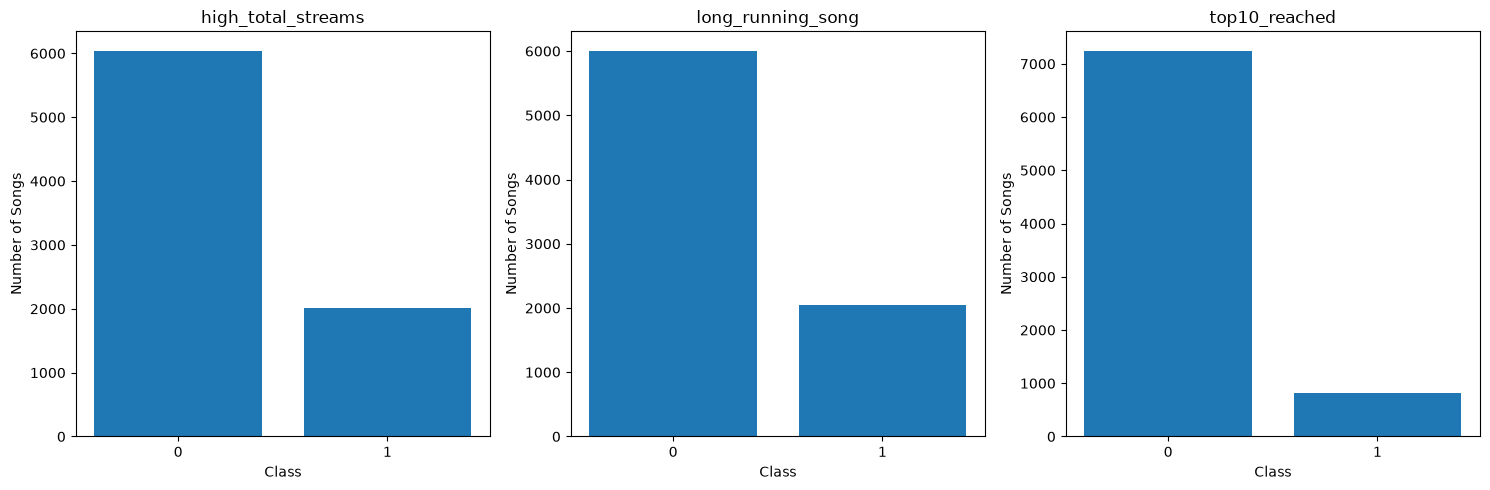

In [63]:
# 8. Visualize Target Balance

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

for ax, target in zip(
    axes,
    TARGET_COLUMNS
):

    counts = df[target].value_counts().sort_index()

    ax.bar(
        counts.index.astype(str),
        counts.values
    )

    ax.set_title(target)
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Songs")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [113]:
# 9. Define Safe Predictor Features - We will use the NLP Features created in Notebook 06/07 

NUMERIC_FEATURES = [
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "meaningful_word_count",
    "lexical_diversity",
    "avg_word_length",
    "lyric_repetition_ratio",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "sentiment_intensity",
    
]

CATEGORICAL_FEATURES = []

MODEL_FEATURES = [
    NUMERIC_FEATURES 
    + CATEGORICAL_FEATURES
]

print(
    "Number of predictor features:",
    len(MODEL_FEATURES)
)

print("Predictor Features:", MODEL_FEATURES)


Number of predictor features: 1
Predictor Features: [['lyrics_char_count', 'lyrics_word_count', 'lyrics_unique_word_count', 'meaningful_word_count', 'lexical_diversity', 'avg_word_length', 'lyric_repetition_ratio', 'sentiment_polarity', 'sentiment_subjectivity', 'sentiment_intensity']]


In [ ]:
# LEAKAGE VALIDATION CELL 

FORBIDDEN_FEATURES = [
    "dominant_topic",
    "topic_probability",
    "total",
    "wks",
    "t10",
    "PkStreams",
    "pk",
    "high_total_streams",
    "long_running_song",
    "to10_reached",
]

invalid_features = [
    col for col in MODEL_FEATURES
    if col in FORBIDDEN_FEATURES
]

assert "lyric_repetition_ratio" in df.columns
assert len(MODEL_FEATURES) == 10
assert not invalid_features, (
    f"Potential leakage detected: {invalid_features}"
)

print("Feature validation passed.")
print("Number of predictors:", len(MODEL_FEATURES))
print("Topic features excluded.")
print("Target and lifetime-performance features excluded.")



Number of predictor features: 11

Numeric:
['lyrics_char_count', 'lyrics_word_count', 'lyrics_unique_word_count', 'meaningful_word_count', 'lexical_diversity', 'avg_word_length', 'sentiment_polarity', 'sentiment_subjectivity', 'sentiment_intensity', 'topic_probability']

Categorical:
['dominant_topic']


In [66]:
# 10. Validate the Predictor Columns

missing_predictors = [
    col
    for col in MODEL_FEATURES
    if col not in df.columns 
]

print("Missing predictor columns:")
print(missing_predictors)

Missing predictor columns:
[]


In [67]:
# 11. Leakage Audit - This is one of the most important sections of the notebook

# We explicitly prohibit outcome-derived variables from entering the predictor matrix

LEAKAGE_COLUMNS = [
    "total",
    "wks",
    "t10",
    "PkStreams",
    "pk",

    "top10_reached",
    "high_total_streams",
    "long_running_song",

    "streams_per_week",
    "peak_streams_per_week",
    "top10_week_ratio",
    "peak_stream_share",

    "log_total",
    "log_wks",
    "log_PkStreams",

    "cluster",
    "segment"
]

In [68]:
# Check 

leakage_in_features = [
    col 
    for col in MODEL_FEATURES
    if col in LEAKAGE_COLUMNS
]

print(
    "Potential leakage features:"
)

print(
    leakage_in_features
)

Potential leakage features:
[]


Why cluster and segment are excluded 

Notebook 08 created them using: wks, t10, pk, PkStreams, total
Therefore they contain information about the eventual outcomes.

Using them here would indirectly leak the target into the model.

In [69]:
# 12. Prepare X and y - for example, start with the high-stream target.abs

TARGET = "high_total_streams"

X = df[MODEL_FEATURES].copy()

y = df[TARGET].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

X shape: (8058, 11)
y shape: (8058,)

Target Distribution:
high_total_streams
0    6043
1    2015
Name: count, dtype: int64


In [70]:
# 13. Train/Test Split 
# Use stratification so both sets preserve approximately the same class distribution

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "\nTraining class distribution:"
)

print(
    y_train.value_counts(
        normalize=True
    ).mul(100).round(2)
)

print(
    "\nTesting class distribution:"
)

print(
    y_test.value_counts(
        normalize=True
    ).mul(100).round(2)
)

Training rows: 6446
Testing rows: 1612

Training class distribution:
high_total_streams
0    74.99
1    25.01
Name: proportion, dtype: float64

Testing class distribution:
high_total_streams
0    75.0
1    25.0
Name: proportion, dtype: float64


### 14. Build the Preprocessing Pipeline

We have: 

Numeric Features

These include:

lyrics_word_count, lexical_diversity, sentiment_polarity 

We'll 
1. replace missing values with the median
2. standardize them

Categorical feature
dominant_topic is a category, not a continuous numerical scale.

For example
Topic 1, Topic 2, Topic 3 ... Topic 8

Topic 8 is not "more" than Topic 1 . Therefore, one-hot encode it

In [71]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [72]:
# 15. Combine the Preprocessing Pipelines

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            categorical_pipeline,
            CATEGORICAL_FEATURES
        )
    ]
)

This ensures preprocessing happens inside the ML pipeline, preventing train/test contamination.

In [73]:
# 16. Establish a Baseline Model - Before evaluating sophisticated algorithms, create a simple baseline

baseline_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)


baseline_pipeline.fit(
    X_train,
    y_train
)

baseline_pred = baseline_pipeline.predict(
    X_test 
)

baseline_prob = baseline_pipeline.predict_proba(
    X_test 
)[:, 1]

In [74]:
# Evaluate 

print(
    classification_report(
        y_test,
        baseline_pred
    )
)

              precision    recall  f1-score   support

           0       0.75      1.00      0.86      1209
           1       0.00      0.00      0.00       403

    accuracy                           0.75      1612
   macro avg       0.38      0.50      0.43      1612
weighted avg       0.56      0.75      0.64      1612



c:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter

The baseline tells us how well a trivial model performs.

# 17. Define Candidate ML Models

We will test 
1) Logistic Regression
2) Random Forest
3) XGBoost
4) LightGBM 

These provide different modeling approaches


In [75]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

In [76]:
# 18. Create Evaluation Function - We'll reuse the same function for all three prediction tasks

def evaluate_model(
    model,
    X_train,
    X_test,
    y_train,
    y_test
):

    start_time = time.time()

    model.fit(
        X_train,
        y_train
    )

    training_time = (
        time.time() - start_time
    )

    predictions = model.predict(
        X_test 
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    metrics = {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_test,
            probabilities
        ),

        "PR_AUC": average_precision_score(
            y_test,
            probabilities
        ),

        "Training_Time": training_time
    }

    return (
        metrics,
        predictions,
        probabilities
    )

In [77]:
# 19. Create a Function for Training All Models

def train_models_for_target(
    df,
    target,
    models,
    model_features,
    preprocessor
):

    X = df[
        model_features
    ].copy()

    y = df[
        target
    ].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    results = []

    fitted_models = {}

    predictions_store = {}

    probabilities_store = {}

    for model_name, estimator in models.items():

        print(
            f"Training {model_name}..."
        )

        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "model",
                    estimator
                )
            ]
        )

        metrics, predictions, probabilities = (
            evaluate_model(
                pipeline,
                X_train,
                X_test,
                y_train,
                y_test
            )
        )

        metrics["Target"] = target
        metrics["Model"] = model_name

        results.append(metrics)

        fitted_models[
            model_name
        ] = pipeline 

        predictions_store[
            model_name
        ] = predictions 

        probabilities_store[
            model_name
        ] = probabilities

    results_df = pd.DataFrame(
        results
    )

    return (
        results_df,
        fitted_models,
        predictions_store,
        probabilities_store,
        X_train,
        X_test,
        y_train,
        y_test
    )

In [78]:
# 20. Train Models - High Total Streams

(
    high_stream_results,
    high_stream_models,
    high_stream_predictions,
    high_stream_probabilities,
    X_train_high,
    X_test_high,
    y_train_high,
    y_test_high    
) = train_models_for_target(
    df=df,
    target="high_total_streams",
    models=models,
    model_features=MODEL_FEATURES,
    preprocessor=preprocessor
)

display(
    high_stream_results.sort_values(
        "ROC_AUC",
        ascending=False
    )
)

Training Logistic Regression...
Training Random Forest...
Training XGBoost...
Training LightGBM...


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time,Target,Model
0,0.586228,0.322102,0.593052,0.417467,0.648100,0.354342,0.024589,high_total_streams,Logistic Regression
2,0.742556,0.418919,0.076923,0.129979,0.632038,0.345063,0.539014,high_total_streams,XGBoost
1,0.682382,0.349862,0.315136,0.331593,0.625932,0.325566,0.732377,high_total_streams,Random Forest
3,0.739454,0.415842,0.104218,0.166667,0.619672,0.334790,0.402515,high_total_streams,LightGBM


In [79]:
# 21. Train Models - Long-Running Songs

(
    longevity_results,
    longevity_models,
    longevity_predictions,
    longevity_probabilities,
    X_train_long,
    X_test_long,
    y_train_long,
    y_test_long
) = train_models_for_target(
    df=df,
    target="long_running_song",
    models=models,
    model_features=MODEL_FEATURES,
    preprocessor=preprocessor
)

display(
    longevity_results.sort_values(
        "ROC_AUC",
        ascending=False
    )
)

Training Logistic Regression...
Training Random Forest...
Training XGBoost...
Training LightGBM...


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time,Target,Model
0,0.599876,0.349552,0.665854,0.458438,0.663613,0.362361,0.048504,long_running_song,Logistic Regression
2,0.735732,0.416667,0.097561,0.158103,0.662414,0.381476,2.146420,long_running_song,XGBoost
1,0.678660,0.371429,0.380488,0.375904,0.655318,0.364256,1.200925,long_running_song,Random Forest
3,0.730769,0.401639,0.119512,0.184211,0.627012,0.346495,2.313417,long_running_song,LightGBM


In [80]:
# 22. Train Models - Top-10 Reach 

(
    top10_results,
    top10_models,
    top10_predictions,
    top10_probabilities,
    X_train_top10,
    X_test_top10,
    y_train_top10,
    y_test_top10
) = train_models_for_target(
    df=df,
    target="top10_reached",
    models=models,
    model_features=MODEL_FEATURES,
    preprocessor=preprocessor
)

display(
    top10_results.sort_values(
        "ROC_AUC",
        ascending=False
    )
)

Training Logistic Regression...
Training Random Forest...
Training XGBoost...
Training LightGBM...


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time,Target,Model
2,0.899504,0.00000,0.000000,0.000000,0.604711,0.136484,2.589921,top10_reached,XGBoost
1,0.874690,0.18750,0.074074,0.106195,0.595170,0.133240,2.940129,top10_reached,Random Forest
3,0.894541,0.10000,0.006173,0.011628,0.585175,0.130383,2.437973,top10_reached,LightGBM
0,0.544045,0.12253,0.574074,0.201954,0.583301,0.122884,0.179710,top10_reached,Logistic Regression


In [81]:
# 23. Combine All results

all_results = pd.concat(
    [
        high_stream_results,
        longevity_results,
        top10_results
    ],
    ignore_index=True 
)

all_results = all_results[
    [
        "Target",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC",
        "Training_Time"
    ]
]

display(
    all_results.sort_values(
        [
            "Target",
            "ROC_AUC"
        ],
        ascending=[
            True,
            False
        ]
    )
)

,Target,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time
0,high_total_streams,Logistic Regression,0.586228,0.322102,0.593052,0.417467,0.648100,0.354342,0.024589
2,high_total_streams,XGBoost,0.742556,0.418919,0.076923,0.129979,0.632038,0.345063,0.539014
1,high_total_streams,Random Forest,0.682382,0.349862,0.315136,0.331593,0.625932,0.325566,0.732377
3,high_total_streams,LightGBM,0.739454,0.415842,0.104218,0.166667,0.619672,0.334790,0.402515
4,long_running_song,Logistic Regression,0.599876,0.349552,0.665854,0.458438,0.663613,0.362361,0.048504
6,long_running_song,XGBoost,0.735732,0.416667,0.097561,0.158103,0.662414,0.381476,2.146420
5,long_running_song,Random Forest,0.678660,0.371429,0.380488,0.375904,0.655318,0.364256,1.200925
7,long_running_song,LightGBM,0.730769,0.401639,0.119512,0.184211,0.627012,0.346495,2.313417
10,top10_reached,XGBoost,0.899504,0.000000,0.000000,0.000000,0.604711,0.136484,2.589921
9,top10_reached,Random Forest,0.874690,0.187500,0.074074,0.106195,0.595170,0.133240,2.940129


In [82]:
# Save Model Results

all_results.to_csv(
    TABLE_DIR / "model_results.csv",
    index=False 
)

print(
    "Saved:",
    TABLE_DIR / "model_results.csv"
)

Saved: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\tables\machine_learning\model_results.csv


### 25. Understand Why We use PR-AUC

For the Top-10 target, the positive class is much smaller than the negative class.

Accuracy can therefore be misleading.

For example, imagine
90% = Did not reach Top 10
10% = Reached Top 10

A model that predicts "No" for everyone could achieve 90% accuracy while being completely useless for finding Top-10 songs.

Therefore, pay particular attention to:

F1, Recall, Precision, PR-AUC, ROC-AUC

For imbalanced targets, PR-AUC is especially informative about positive-class identification.


In [83]:
# Confusion Matrix Function

def plot_confusion_matrix(
    y_true,
    y_pred,
    title,
    filename
):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(
        figsize=(6, 5)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.xlabel(
        "Predicted"
    )

    plt.ylabel(
        "Actual"
    )

    plt.title(
        title 
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [84]:
# 27. Confusion Matrix - High Streams - For now, use the model with the highest ROC-AUC from the results table.abs

best_high_stream_model_name = (
    high_stream_results
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .iloc[0]["Model"]
)

print(
    "Highest ROC_AUC model:",
    best_high_stream_model_name
)

Highest ROC_AUC model: Logistic Regression


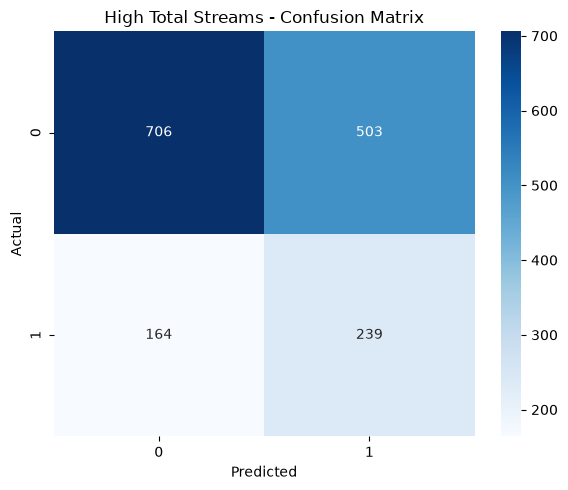

In [85]:
# Then

plot_confusion_matrix(
    y_test_high,
    high_stream_predictions[
        best_high_stream_model_name
    ],
    "High Total Streams - Confusion Matrix",
    "high_stream_confusion_matrix.png"
)

Highest ROC_AUC model: Logistic Regression


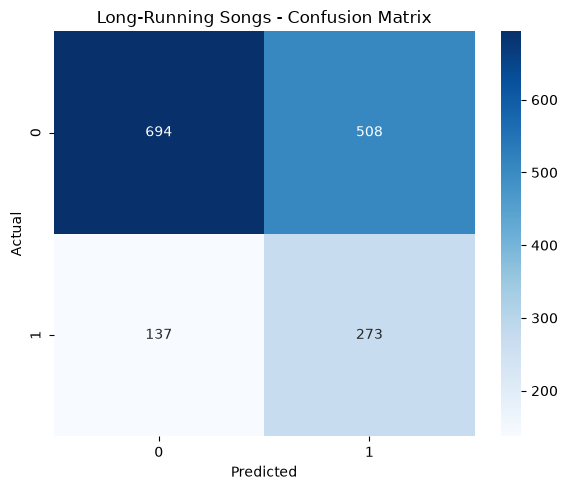

In [86]:
# 28. Confusion Matrix - Long Running

best_longevity_model_name = (
    longevity_results
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .iloc[0]["Model"]
)

print(
    "Highest ROC_AUC model:",
    best_longevity_model_name
)

plot_confusion_matrix(
    y_test_long,
    longevity_predictions[
        best_longevity_model_name
    ],
    "Long-Running Songs - Confusion Matrix",
    "longevity_confusion_matrix.png"
)

Highest ROC-AUC model: XGBoost


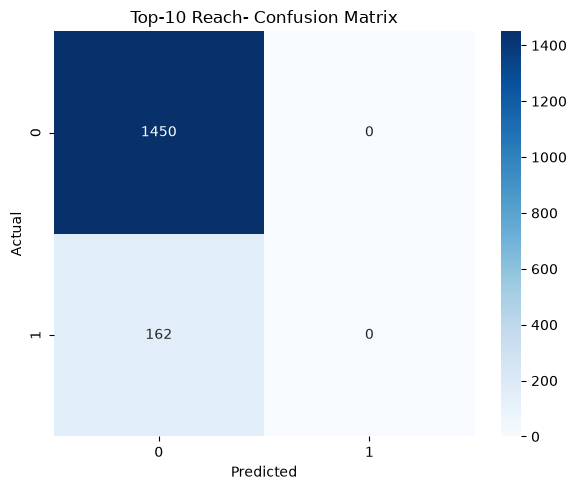

In [87]:
# 29. Confusion Matrix - Top 10

best_top10_model_name = (
    top10_results
    .sort_values( 
        "ROC_AUC",
        ascending=False 
    )
    .iloc[0]["Model"]
)

print(
    "Highest ROC-AUC model:",
    best_top10_model_name
)

plot_confusion_matrix(
    y_test_top10,
    top10_predictions[
        best_top10_model_name
    ],
    "Top-10 Reach- Confusion Matrix",
    "top10_confusion_matrix.png"
)

In [88]:
# 30. ROC Curves - Create a reusable function


def plot_roc_curves(
    y_test,
    probabilities,
    title,
    filename
):

    plt.figure(
        figsize=(9, 7)
    )

    for model_name, probs in probabilities.items():

        fpr, tpr, _ = roc_curve(
            y_test,
            probs
        )

        auc = roc_auc_score(
            y_test,
            probs
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{model_name} (AUC={auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        title
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

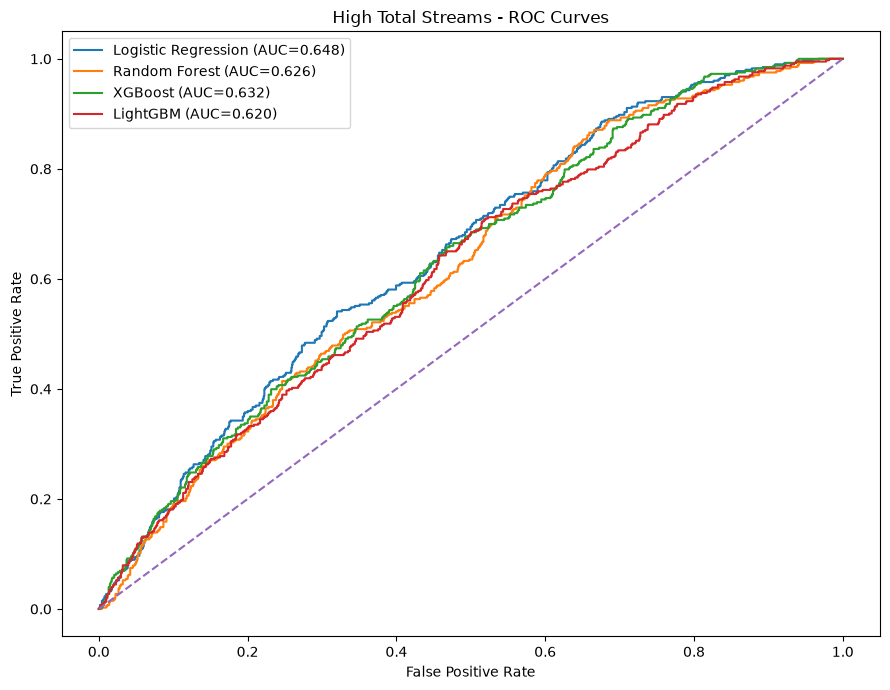

In [89]:
# 31. High-Stream ROC Curves

plot_roc_curves(
    y_test_high,
    high_stream_probabilities,
    "High Total Streams - ROC Curves",
    "high_stream_roc_curves.png"
)

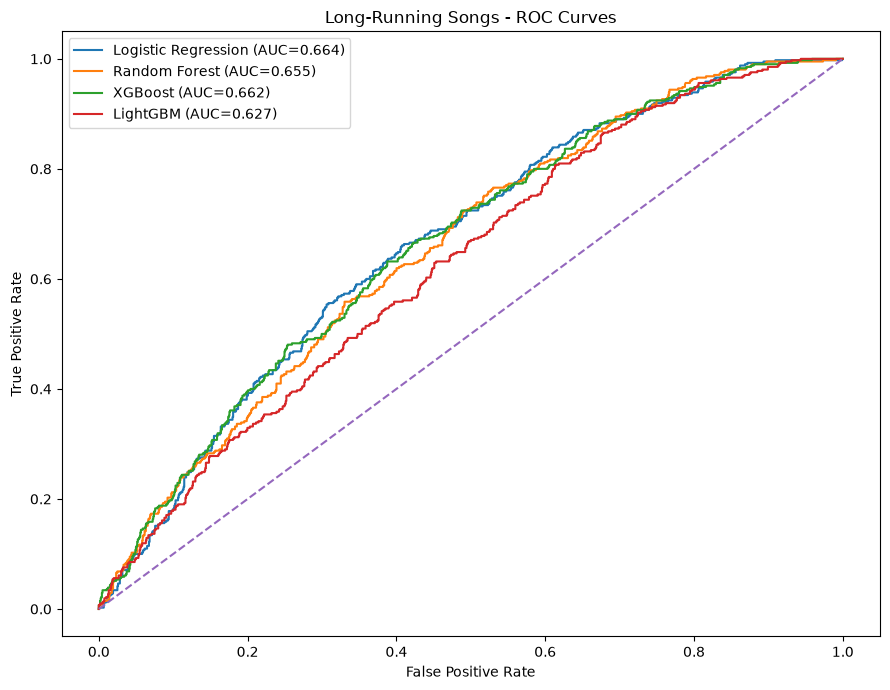

In [90]:
# 32. Long-Running ROC Curves

plot_roc_curves(
    y_test_long,
    longevity_probabilities,
    "Long-Running Songs - ROC Curves",
    "longevity_roc_curves.png"
)

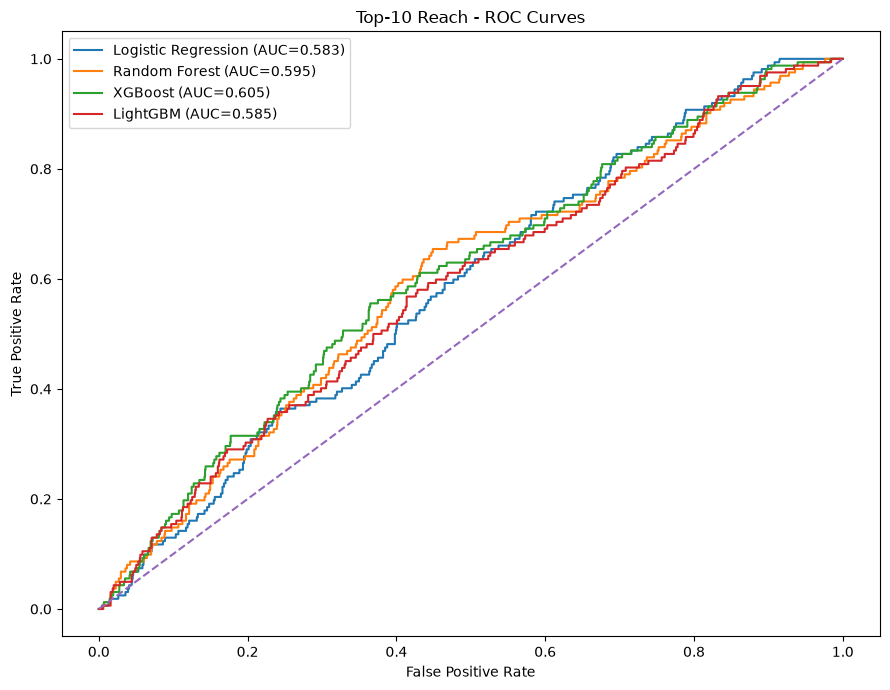

In [91]:
# 33. Top-10 ROC Curves

plot_roc_curves(
    y_test_top10,
    top10_probabilities,
    "Top-10 Reach - ROC Curves",
    "top10_roc_curves.png"
)

In [92]:
# 34. Precision-Recall Curves - This is particularly useful for Top-10 classification

def plot_pr_curves(
    y_test,
    probabilities,
    title,
    filename
):

    plt.figure(
        figsize=(9, 7)
    )

    baseline = y_test.mean()

    for model_name, probs in probabilities.items():

        precision, recall, _ = (
            precision_recall_curve(
                y_test,
                probs
            )
        )

        ap = average_precision_score(
            y_test,
            probs
        )

        plt.plot(
            recall,
            precision,
            label=f"{model_name} (AP={ap:.3f})"
        )

    plt.axhline(
        baseline,
        linestyle="--",
        label=f"Baseline={baseline:.3f}"
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        title
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

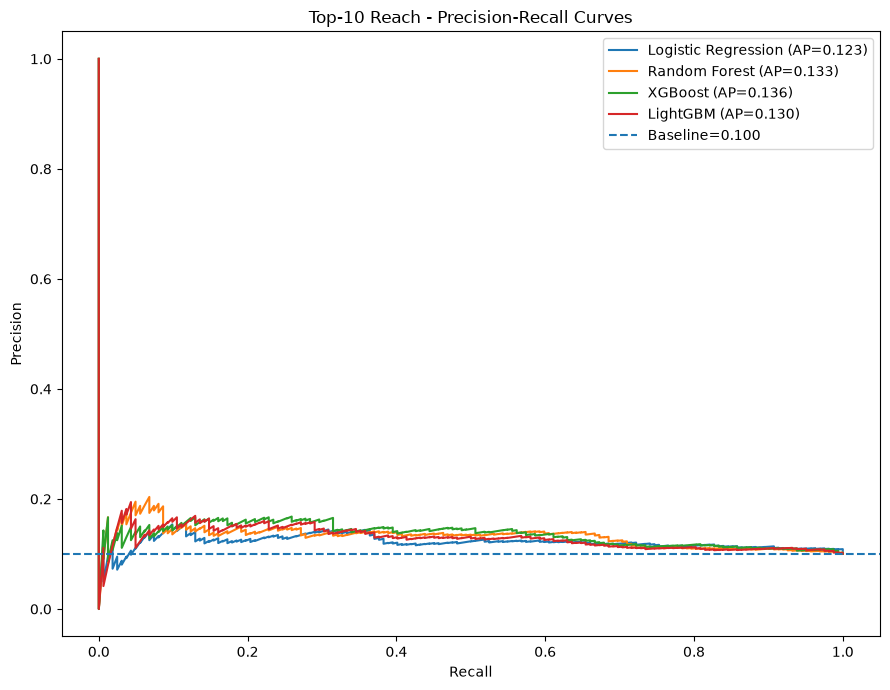

In [93]:
# 35. Top-10 Precision-Recall Curve

plot_pr_curves(
    y_test_top10,
    top10_probabilities,
    "Top-10 Reach - Precision-Recall Curves",
    "top10_precision_recall_curves.png"
)

In [94]:
# 36. Cross-Validation
# A single train/test split can sometimes give unstable results
# We'll use 5-fold Stratified Cross-Validation

cv= StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [95]:
# 37. Cross-Validate the High-Stream Models

cv_results_high = []

X_high = df[
    MODEL_FEATURES
]

y_high = df[
    "high_total_streams"
].astype(int)

for model_name, estimator in models.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                estimator
            )
        ]
    )

    scores = cross_validate(
        pipeline,
        X_high,
        y_high,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )


    cv_results_high.append({

        "Model": model_name,

        "Mean_Accuracy": scores[
            "test_accuracy"
        ].mean(),

        "Mean_Precision": scores[
            "test_precision"
        ].mean(),

        "Mean_Recall": scores[
            "test_recall"
        ].mean(),

        "Mean_F1": scores[
            "test_f1"
        ].mean(),

        "Mean_ROC_AUC": scores[
            "test_roc_auc"
        ].mean(),

        "Std_ROC_AUC": scores[
            "test_roc_auc"
        ].std()

    })

cv_results_high = pd.DataFrame(
    cv_results_high
)

display(
    cv_results_high.sort_values(
        "Mean_ROC_AUC",
        ascending=False
    )
)

,Model,Mean_Accuracy,Mean_Precision,Mean_Recall,Mean_F1,Mean_ROC_AUC,Std_ROC_AUC
0,Logistic Regression,0.584265,0.328226,0.632258,0.432060,0.648470,0.013274
2,XGBoost,0.740134,0.397242,0.078908,0.131486,0.624239,0.011497
1,Random Forest,0.675727,0.339521,0.313151,0.325607,0.620111,0.009184
3,LightGBM,0.730454,0.362451,0.101737,0.158725,0.613353,0.013779


In [96]:
# 38. Repeat CV for the Other Targets

def cross_validate_models(
    df,
    target,
    models,
    model_features,
    preprocessor,
    cv
):

    X = df[
        model_features 
    ]

    y = df[
        target
    ].astype(int)

    results = []

    for model_name, estimator in models.items():

        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "model",
                    estimator
                )
            ]
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=[
                "accuracy",
                "precision",
                "recall",
                "f1",
                "roc_auc"
            ],
            n_jobs=-1
        )

        results.append({
            "Target": target,
            "Model": model_name,

            "Mean_Accuracy":
                scores[
                    "test_accuracy"
                ].mean(),

            "Mean_Precision":
                scores[
                    "test_precision"
                ].mean(),

            "Mean_Recall":
                scores[
                    "test_recall"
                ].mean(),

            "Mean_F1":
                scores[
                    "test_f1"
                ].mean(),

            "Mean_ROC_AUC":
                scores[
                    "test_roc_auc"
                ].mean(),

            "Std_ROC_AUC":
                scores[
                    "test_roc_auc"
                ].std(),

        })

    return pd.DataFrame(
        results
    )

In [97]:
cv_longevity = cross_validate_models(
    df,
    "long_running_song",
    models,
    MODEL_FEATURES,
    preprocessor,
    cv
)


cv_top10 = cross_validate_models(
    df,
    "top10_reached",
    models,
    MODEL_FEATURES,
    preprocessor,
    cv
)

In [98]:
# Combine

cv_all_results = pd.concat(
    [
        cv_results_high.assign(
            Target = "high_total_streams"
        ),
        cv_longevity,
        cv_top10
    ],
    ignore_index=True
)

display(
    cv_all_results.sort_values(
        [
            "Target",
            "Mean_ROC_AUC"
        ],
        ascending=[
            True,
            False
        ]
    )
)

,Model,Mean_Accuracy,Mean_Precision,Mean_Recall,Mean_F1,Mean_ROC_AUC,Std_ROC_AUC,Target
0,Logistic Regression,0.584265,0.328226,0.632258,0.432060,0.648470,0.013274,high_total_streams
2,XGBoost,0.740134,0.397242,0.078908,0.131486,0.624239,0.011497,high_total_streams
1,Random Forest,0.675727,0.339521,0.313151,0.325607,0.620111,0.009184,high_total_streams
3,LightGBM,0.730454,0.362451,0.101737,0.158725,0.613353,0.013779,high_total_streams
4,Logistic Regression,0.600769,0.347991,0.648953,0.452892,0.665649,0.006724,long_running_song
6,XGBoost,0.736536,0.425650,0.098984,0.160360,0.642014,0.005663,long_running_song
5,Random Forest,0.670763,0.354505,0.357398,0.355775,0.630818,0.002905,long_running_song
7,LightGBM,0.729090,0.399062,0.125318,0.190374,0.628555,0.006997,long_running_song
8,Logistic Regression,0.542321,0.133381,0.646914,0.221098,0.614396,0.014868,top10_reached
10,XGBoost,0.897865,0.166667,0.003704,0.007244,0.598864,0.017364,top10_reached


In [99]:
# 39. Save Cross-Validation Results

cv_all_results.to_csv(
    TABLE_DIR / "cross_validation_results.csv",
    index=False 
)


### 40. Feature Importance - Tree Models

Now we want to answer:
Which lyric features contribute most strongly to the model?

This will become even more powerful in Notebook 11 with SHAP

First, let's extract features names after preprocessing.

In [100]:
best_high_model = high_stream_models[
    best_high_stream_model_name
]

preprocessor_fitted = (
    best_high_model
    .named_steps[
        "preprocessor"
    ]
)

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

print(
    "Number of transformed features:",
    len(feature_names)
)

print(
    feature_names
)

Number of transformed features: 18
['numeric__lyrics_char_count' 'numeric__lyrics_word_count'
 'numeric__lyrics_unique_word_count' 'numeric__meaningful_word_count'
 'numeric__lexical_diversity' 'numeric__avg_word_length'
 'numeric__sentiment_polarity' 'numeric__sentiment_subjectivity'
 'numeric__sentiment_intensity' 'numeric__topic_probability'
 'categorical__dominant_topic_1' 'categorical__dominant_topic_2'
 'categorical__dominant_topic_3' 'categorical__dominant_topic_4'
 'categorical__dominant_topic_5' 'categorical__dominant_topic_6'
 'categorical__dominant_topic_7' 'categorical__dominant_topic_8']


In [101]:
# 41. Extract LightGBM / Random Forest Importance
# If the selected model is tree based.

final_estimator = (
    best_high_model
    .named_steps[
        "model"
    ]
)

if hasattr(
    final_estimator,
    "feature_importances_"
):

    importance = (
        final_estimator
        .feature_importances_
    )

    feature_importances_ = pd.DataFrame({
        "feature": feature_names,
        "importance": importance 
    }).sort_values(
        "importance",
        ascending=False
    )

    display(
        feature_importance.head(20)
    )

In [102]:
# 42. Plot Feature Importance

if "feature_importance" in locals():

    top_features = (
        feature_importance
        .head(15)
        .sort_values(
            "importance"
        )
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        top_features["feature"],
        top_features["importance"]
    )

    plt.xlabel(
        "Importance"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        "Top Features - High Total Streams Model"
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "feature_importance_high_streams.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [103]:
# 43. Save Feature Importance

if "feature_importance" in locals():

    feature_importance.to_csv(
        TABLE_DIR / "feature_importance_high_streams.csv",
        index=False
    )

In [104]:
# 44. Save Trained Models - Save each fitted model so Notebook 10/11 can reuse them

for model_name, model in high_stream_models.items():

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    joblib.dump(
        model,
        MODEL_DIR
        / f"high_streams_{safe_name}.joblib"
    )

In [105]:
# Longevity

for model_name, model in longevity_models.items():

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    joblib.dump(
        model,
        MODEL_DIR
        / f"longevity_{safe_name}.joblib"
    )

In [106]:
# Top-10

for model_name, model in top10_models.items():

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    joblib.dump(
        model,
        MODEL_DIR 
        / f"top10_{safe_name}.joblib"
    )

In [107]:
# 45. Save Test Predictions

high_predictions_df = pd.DataFrame({
    "actual": y_test_high.reset_index(drop=True)
})

for model_name, predictions in (
    high_stream_predictions.items()
):

    high_predictions_df[
        f"{model_name}_prediction"
    ] = predictions 

for model_name, probabilities in (
    high_stream_probabilities.items()
):

    high_predictions_df[
        f"{model_name}_probability"
    ] = probabilities

In [108]:
# Save

high_predictions_df.to_csv(
    TABLE_DIR / "high_stream_test_predictions.csv",
    index=False
)

In [109]:
# Do the same for other targets

longevity_predictions_df = pd.DataFrame({
    "actual": y_test_long.reset_index(drop=True)
})

for model_name, predictions in (
    longevity_predictions.items()
):

    longevity_predictions_df[
        f"{model_name}_prediction"
    ] = predictions 

for model_name, probabilities in (
    longevity_probabilities.items()
):

    longevity_predictions_df[
        f"{model_name}_probability"
    ] = probabilities

longevity_predictions_df.to_csv(
    TABLE_DIR / "longevity_test_predictions.csv",
    index=False
)

In [110]:
# Top-10

top10_predictions_df = pd.DataFrame({
    "actual": y_test_top10.reset_index(drop=True)
})

for model_name, predictions in (
    top10_predictions.items()
):

    top10_predictions_df[
        f"{model_name}_prediction"
    ] = predictions

for model_name, probabilities in (
    top10_probabilities.items()
):

    top10_predictions_df[
        f"{model_name}_probability"
    ] = probabilities

top10_predictions_df.to_csv(
    TABLE_DIR / "top10_test_predictions.csv",
    index=False
)

In [111]:
# 46. Final Model Results Table

# Create a compact portfolio table

model_summary = (
    all_results
    .sort_values(
        [
            "Target",
            "ROC_AUC"
        ],
        ascending=[
            True,
            False 
        ]
    )
)

display(
    model_summary.round(4)
)

,Target,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time
0,high_total_streams,Logistic Regression,0.5862,0.3221,0.5931,0.4175,0.6481,0.3543,0.0246
2,high_total_streams,XGBoost,0.7426,0.4189,0.0769,0.1300,0.6320,0.3451,0.5390
1,high_total_streams,Random Forest,0.6824,0.3499,0.3151,0.3316,0.6259,0.3256,0.7324
3,high_total_streams,LightGBM,0.7395,0.4158,0.1042,0.1667,0.6197,0.3348,0.4025
4,long_running_song,Logistic Regression,0.5999,0.3496,0.6659,0.4584,0.6636,0.3624,0.0485
6,long_running_song,XGBoost,0.7357,0.4167,0.0976,0.1581,0.6624,0.3815,2.1464
5,long_running_song,Random Forest,0.6787,0.3714,0.3805,0.3759,0.6553,0.3643,1.2009
7,long_running_song,LightGBM,0.7308,0.4016,0.1195,0.1842,0.6270,0.3465,2.3134
10,top10_reached,XGBoost,0.8995,0.0000,0.0000,0.0000,0.6047,0.1365,2.5899
9,top10_reached,Random Forest,0.8747,0.1875,0.0741,0.1062,0.5952,0.1332,2.9401


In [112]:
# 47. Final Validation

print("=" * 70)
print("NOTEBOOK 09 VALIDATION")
print("=" * 70)

print(
    "\nDataset:",
    df.shape
)

print(
    "\nPredictor count:",
    len(MODEL_FEATURES)
)

print(
    "\nLeakage features:",
    leakage_in_features
)

print(
    "\nTargets:",
    TARGET_COLUMNS
)

print(
    "\nModel results:",
    all_results.shape
)

print(
    "\nCross-validation results:",
    cv_all_results.shape
)

NOTEBOOK 09 VALIDATION

Dataset: (8058, 51)

Predictor count: 11

Leakage features: []

Targets: ['high_total_streams', 'long_running_song', 'top10_reached']

Model results: (12, 9)

Cross-validation results: (12, 8)


### 48. Final Conclusions

### Machine Learning Findings

Three classification tasks were investigated:

### 1. High Total Streams

The models investigate whether lyrics characteristics can distinguish songs that eventually reach the upper quartile of cumulative
streaming performance.

### 2. Long-Running Songs

The models investigate whether lyric characteristics are associated with songs that maintain a longer- than-typical presence on the global chart.

### 3. Top-10 Reach 

The models investigate whether lyric characteristics are associated with eventual Top-10 chart achievement.

### Modeling Approach

Multiple algorithms were evaluated:

- Logistic Regression
- Random Forest
- XGBoost
- LightGBM 

All models were implemented using preprocessing pipelines.

Numeric lyric features were median-imputed and standardized.

Dominant Lyric topic was treated as a categorical feature and one-hot encoded.

### Leakage Control

Lifetime chart-performance variables were explicitly excluded from the predictor matrix.

Excluded variables included:

- Total streams
- Chart weeks
- Top-10 weeks
- Peak streams
- Peak position
- Streams per week
- Peak stream share
- Top-10 ratio
- Cluster labels
- Segment labels

This prevents the model from using the eventual outcome to predict itself

### Evaluation

Because some classes are imbalanced, evaluation uses:

- Accuracy
- Precision
- Recall
- F1
- ROC_AUC
- PR_AUC

Five-fold stratified cross-validation was also performed to assess model stability.

### Important Interpretation

These models should be interpreted as studying associations between lyric characteristics and eventual chart outcomes.

They do not establish that lyrics cause streaming success.

The dataset also does not contain a song-release prediction timestamp, so the experiment should be interpreted as a real-time forecasting system.

### Next Step

Notebook 10 will perform a structured comparison of machine-learning models across the three prediction tasks.

Notebook 11 will use SHAP to explain which lyric features influence individual model predictions.

Because we had several feature_df state problems in Notebook 07, Notebook 09 intentionally loads the saved spotify_feature_engineered.csv rather than depending on whatever variables happen to remain in the Jupyter kernel. This should make the notebook much more reproducible.

If the spotify_feature_engineered.csv does not contain the three target columns (high_total_streams, long_running_song, top10_reached), don't recreate the entire notebook- run the target-definition section from Notebook 07 first, save the feature-engineered file, and then start Notebook 09 from the loading cell.